# Fase 4 — Modelagem (CRISP-DM)

**Pergunta de negócio:** Quais regiões administrativas do Distrito Federal apresentam os maiores registros de violência doméstica de 2024 a 2025?

A pergunta é **descritiva**: quer saber *onde* os registros se concentram e *como* mudaram, não prever casos futuros. As técnicas foram escolhidas para responder a isso, seguindo o checklist da fase (selecionar técnicas, gerar design de teste, avaliar):

| Técnica | Pergunta que responde |
|---|---|
| 4.1 Ranking e participação | Quais RAs têm mais registros em 2025 e em 2024? |
| 4.2 Análise de Pareto (concentração) | Quantas RAs concentram a maior parte dos registros? |
| 4.3 Variação 2024 → 2025 | Onde os registros mais cresceram ou caíram? |
| 4.4 Correlação de Spearman entre rankings | O ranking é estável ao longo dos anos? (teste de robustez) |
| 4.5 Agrupamento K-means (aprendizado não supervisionado) | Quais RAs têm perfis parecidos de volume e tendência? |

Semente aleatória: **42**.

In [1]:
import platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import spearmanr
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

ANO_BASE, ANO_ALVO = 2024, 2025
SEED = 42
RAIZ = Path('..').resolve()
FIG = RAIZ / 'figuras'; FIG.mkdir(exist_ok=True)

# paleta: azul = série principal, laranja = destaque, cinza = demais
AZUL, LARANJA, VERMELHO, CINZA, TINTA, TINTA2 = '#2a78d6', '#eb6834', '#e34948', '#b5b3ad', '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': CINZA, 'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2,
                     'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.6, 'axes.axisbelow': True})
FONTE = 'Fonte: SSP-DF, Banco Millenium (COOAFESP/SGI). Elaboração própria.'

print('Python', platform.python_version(), '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__,
      '| matplotlib', matplotlib.__version__)

Python 3.13.18 | pandas 3.0.5 | scikit-learn 1.9.1 | matplotlib 3.11.2


In [2]:
base = pd.read_csv(RAIZ / 'dados' / 'processados' / 'violencia_domestica_ra.csv')
anual = base[base['periodo'] == 'Anual']
tab = anual.pivot(index='ra', columns='ano', values='registros')
assert {ANO_BASE, ANO_ALVO} <= set(tab.columns), 'A base precisa ter os dois anos analisados'
print('Anos disponíveis (anual):', list(tab.columns))
print(f'Total DF {ANO_BASE}: {int(tab[ANO_BASE].sum()):,} | {ANO_ALVO}: {int(tab[ANO_ALVO].sum()):,}'.replace(',', '.'))

Anos disponíveis (anual): [2018, 2019, 2020, 2021, 2022, 2024, 2025]
Total DF 2024: 21.721 | 2025: 23.066


## 4.1 Ranking das Regiões Administrativas

In [3]:
rank = pd.DataFrame({
    f'reg_{ANO_BASE}': tab[ANO_BASE].astype(int), f'reg_{ANO_ALVO}': tab[ANO_ALVO].astype(int),
})
rank[f'part_{ANO_ALVO}_%'] = (100 * rank[f'reg_{ANO_ALVO}'] / rank[f'reg_{ANO_ALVO}'].sum()).round(1)
rank[f'pos_{ANO_BASE}'] = rank[f'reg_{ANO_BASE}'].rank(ascending=False, method='min').astype(int)
rank[f'pos_{ANO_ALVO}'] = rank[f'reg_{ANO_ALVO}'].rank(ascending=False, method='min').astype(int)
rank['soma_2_anos'] = rank[f'reg_{ANO_BASE}'] + rank[f'reg_{ANO_ALVO}']
rank['pos_2_anos'] = rank['soma_2_anos'].rank(ascending=False, method='min').astype(int)
rank = rank.sort_values(f'pos_{ANO_ALVO}')
rank.head(10)

,reg_2024,reg_2025,part_2025_%,pos_2024,pos_2025,soma_2_anos,pos_2_anos
ra,,,,,,,
Ceilândia,2922,3135,13.6,1,1,6057,1
Planaltina,1702,1951,8.5,2,2,3653,2
Samambaia,1691,1809,7.8,3,3,3500,3
Taguatinga,1277,1339,5.8,4,4,2616,4
Recanto das Emas,1156,1303,5.6,6,5,2459,5
Gama,1158,1238,5.4,5,6,2396,6
Sol Nascente/Pôr do Sol,1093,1233,5.3,8,7,2326,8
Santa Maria,1145,1198,5.2,7,8,2343,7
São Sebastião,1031,1086,4.7,10,9,2117,9


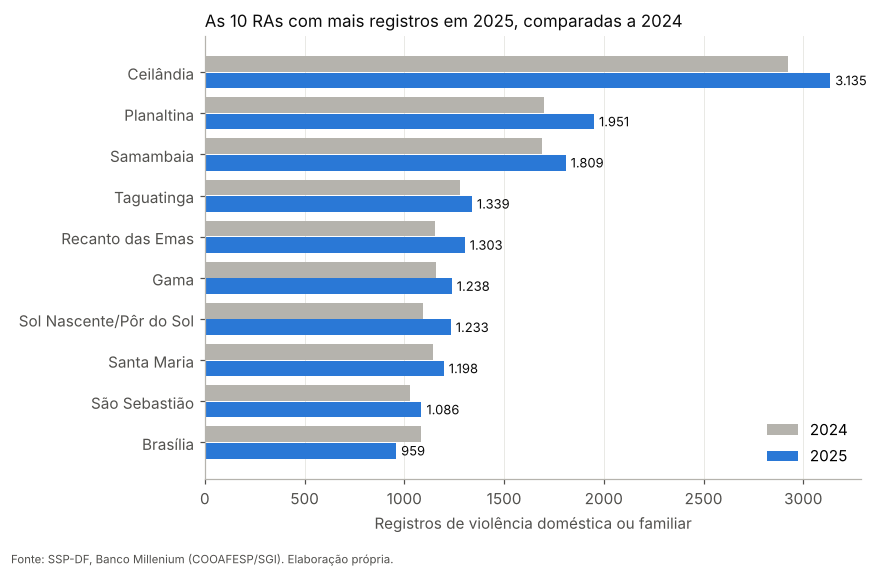

In [4]:
top = rank.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.2))
y = np.arange(len(top))
ax.barh(y + 0.2, top[f'reg_{ANO_BASE}'], height=0.38, color=CINZA, label=str(ANO_BASE))
ax.barh(y - 0.2, top[f'reg_{ANO_ALVO}'], height=0.38, color=AZUL, label=str(ANO_ALVO))
for yi, v in zip(y, top[f'reg_{ANO_ALVO}']):
    ax.text(v + 25, yi - 0.2, f'{v:,}'.replace(',', '.'), va='center', fontsize=8.5, color=TINTA)
ax.set_yticks(y, top.index)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Registros de violência doméstica ou familiar')
ax.set_title(f'As 10 RAs com mais registros em {ANO_ALVO}, comparadas a {ANO_BASE}', loc='left', color=TINTA, fontsize=11)
ax.legend(frameon=False, loc='lower right')
fig.text(0.01, 0.005, FONTE, fontsize=7.5, color=TINTA2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / 'fig1_top10_ras.png', bbox_inches='tight'); plt.show()

## 4.2 Concentração — análise de Pareto

Em 2025: as 10 maiores RAs concentram 66.1% dos registros.
7 RAs somam metade dos registros; 15 RAs somam 80%.


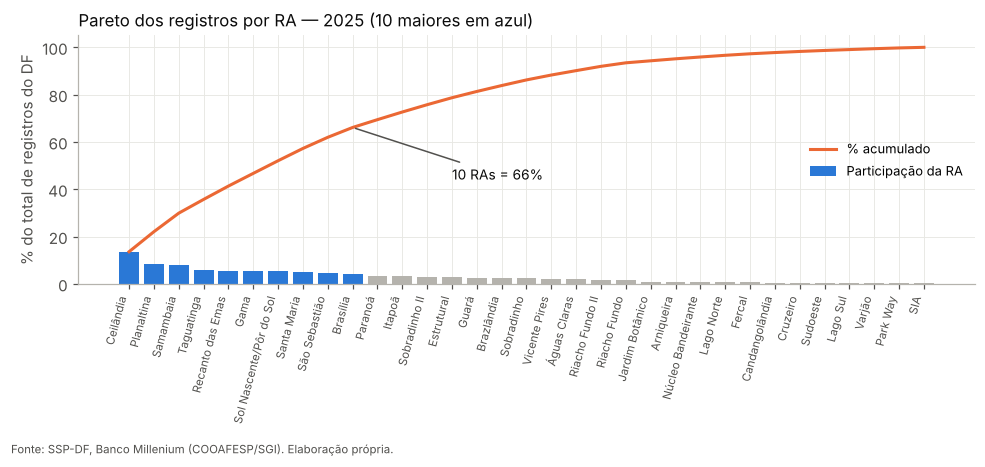

In [5]:
ordem = rank[f'reg_{ANO_ALVO}'].sort_values(ascending=False)
acum = 100 * ordem.cumsum() / ordem.sum()
top10_pct = acum.iloc[9]
n_50 = int((acum < 50).sum() + 1)
n_80 = int((acum < 80).sum() + 1)
print(f'Em {ANO_ALVO}: as 10 maiores RAs concentram {top10_pct:.1f}% dos registros.')
print(f'{n_50} RAs somam metade dos registros; {n_80} RAs somam 80%.')

fig, ax = plt.subplots(figsize=(9, 4.2))
part = 100 * ordem / ordem.sum()
cores = [AZUL if i < 10 else CINZA for i in range(len(ordem))]
ax.bar(range(len(ordem)), part.values, color=cores, width=0.8, label='Participação da RA')
ax.plot(range(len(ordem)), acum.values, color=LARANJA, lw=2, label='% acumulado')
ax.set_xticks(range(len(ordem)), ordem.index, rotation=75, ha='right', fontsize=7.5)
ax.set_ylim(0, 105); ax.set_ylabel('% do total de registros do DF')
ax.annotate(f'10 RAs = {top10_pct:.0f}%', (9, top10_pct), xytext=(13, top10_pct - 22), color=TINTA,
            arrowprops=dict(arrowstyle='-', color=TINTA2), fontsize=9)
ax.legend(frameon=False, loc='center right', fontsize=8.5)
ax.set_title(f'Pareto dos registros por RA — {ANO_ALVO} (10 maiores em azul)', loc='left', color=TINTA, fontsize=11)
fig.text(0.01, 0.005, FONTE, fontsize=7.5, color=TINTA2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / 'fig2_pareto.png', bbox_inches='tight'); plt.show()

## 4.3 Variação entre 2024 e 2025

In [6]:
rank['var_abs'] = rank[f'reg_{ANO_ALVO}'] - rank[f'reg_{ANO_BASE}']
rank['var_pct'] = (100 * rank['var_abs'] / rank[f'reg_{ANO_BASE}']).round(1)
total_b, total_a = rank[f'reg_{ANO_BASE}'].sum(), rank[f'reg_{ANO_ALVO}'].sum()
print(f'DF: {total_b:,} -> {total_a:,} ({total_a-total_b:+,}; {100*(total_a-total_b)/total_b:+.1f}%)'.replace(',', '.'))
print('Maiores aumentos absolutos:')
display(rank.sort_values('var_abs', ascending=False)[[f'reg_{ANO_BASE}', f'reg_{ANO_ALVO}', 'var_abs', 'var_pct']].head(5))
print('Maiores quedas absolutas:')
display(rank.sort_values('var_abs')[[f'reg_{ANO_BASE}', f'reg_{ANO_ALVO}', 'var_abs', 'var_pct']].head(5))

DF: 21.721 -> 23.066 (+1.345; +6.2%)
Maiores aumentos absolutos:


,reg_2024,reg_2025,var_abs,var_pct
ra,,,,
Planaltina,1702,1951,249,14.6
Ceilândia,2922,3135,213,7.3
Recanto das Emas,1156,1303,147,12.7
Sol Nascente/Pôr do Sol,1093,1233,140,12.8
Estrutural,557,680,123,22.1


Maiores quedas absolutas:


,reg_2024,reg_2025,var_abs,var_pct
ra,,,,
Brasília,1084,959,-125,-11.5
Águas Claras,484,430,-54,-11.2
Vicente Pires,504,476,-28,-5.6
Sudoeste,119,97,-22,-18.5
Cruzeiro,124,108,-16,-12.9


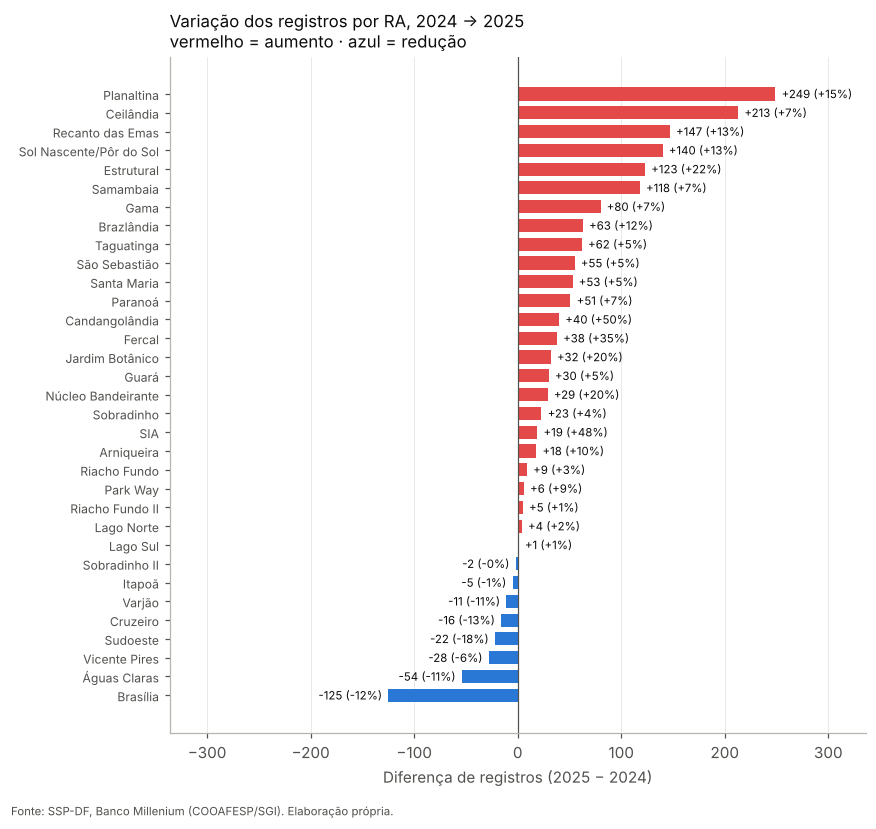

In [7]:
v = rank.sort_values('var_abs')
fig, ax = plt.subplots(figsize=(8, 7.5))
ax.barh(v.index, v['var_abs'], color=[VERMELHO if x > 0 else AZUL for x in v['var_abs']], height=0.7)
ax.axvline(0, color=TINTA2, lw=0.8)
for i, (val, pct) in enumerate(zip(v['var_abs'], v['var_pct'])):
    ax.text(val + (6 if val >= 0 else -6), i, f'{int(val):+d} ({pct:+.0f}%)', va='center',
            ha='left' if val >= 0 else 'right', fontsize=7.5, color=TINTA)
ax.grid(axis='y', visible=False)
ax.tick_params(axis='y', labelsize=8)
ax.set_xlabel(f'Diferença de registros ({ANO_ALVO} − {ANO_BASE})')
ax.set_title(f'Variação dos registros por RA, {ANO_BASE} → {ANO_ALVO}\n'
             'vermelho = aumento · azul = redução', loc='left', color=TINTA, fontsize=11)
lim = v['var_abs'].abs().max() * 1.35
ax.set_xlim(-lim, lim)
fig.text(0.01, 0.005, FONTE, fontsize=7.5, color=TINTA2)
fig.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(FIG / 'fig3_variacao.png', bbox_inches='tight'); plt.show()

## 4.4 Estabilidade do ranking ao longo dos anos (Spearman)

Para saber se o resultado de 2024–2025 é um retrato pontual ou um padrão, comparamos o ranking das RAs entre anos com a **correlação de postos de Spearman** (ρ = 1 indica ranking idêntico). Usamos só os anos com 33 RAs.

In [8]:
anos33 = [a for a in tab.columns if tab[a].notna().sum() == 33]
rho = pd.DataFrame(index=anos33, columns=anos33, dtype=float)
for a in anos33:
    for b in anos33:
        rho.loc[a, b] = spearmanr(tab[a], tab[b]).statistic
print('Correlação de Spearman entre rankings anuais (33 RAs):')
display(rho.round(3))

top5 = {a: list(tab[a].sort_values(ascending=False).head(5).index) for a in tab.columns}
pd.DataFrame(top5, index=[f'{i}º' for i in range(1, 6)])

Correlação de Spearman entre rankings anuais (33 RAs):


,2019,2020,2021,2022,2024,2025
2019,1.000,0.989,0.975,0.967,0.969,0.965
2020,0.989,1.000,0.978,0.971,0.968,0.973
2021,0.975,0.978,1.000,0.989,0.987,0.986
2022,0.967,0.971,0.989,1.000,0.989,0.989
2024,0.969,0.968,0.987,0.989,1.000,0.992
2025,0.965,0.973,0.986,0.989,0.992,1.000


,2018,2019,2020,2021,2022,2024,2025
1º,Ceilândia,Ceilândia,Ceilândia,Ceilândia,Ceilândia,Ceilândia,Ceilândia
2º,Planaltina,Planaltina,Planaltina,Planaltina,Planaltina,Planaltina,Planaltina
3º,Samambaia,Samambaia,Samambaia,Samambaia,Samambaia,Samambaia,Samambaia
4º,Taguatinga,Gama,Taguatinga,Taguatinga,Taguatinga,Taguatinga,Taguatinga
5º,Recanto das Emas,Taguatinga,Gama,Recanto das Emas,Recanto das Emas,Gama,Recanto das Emas


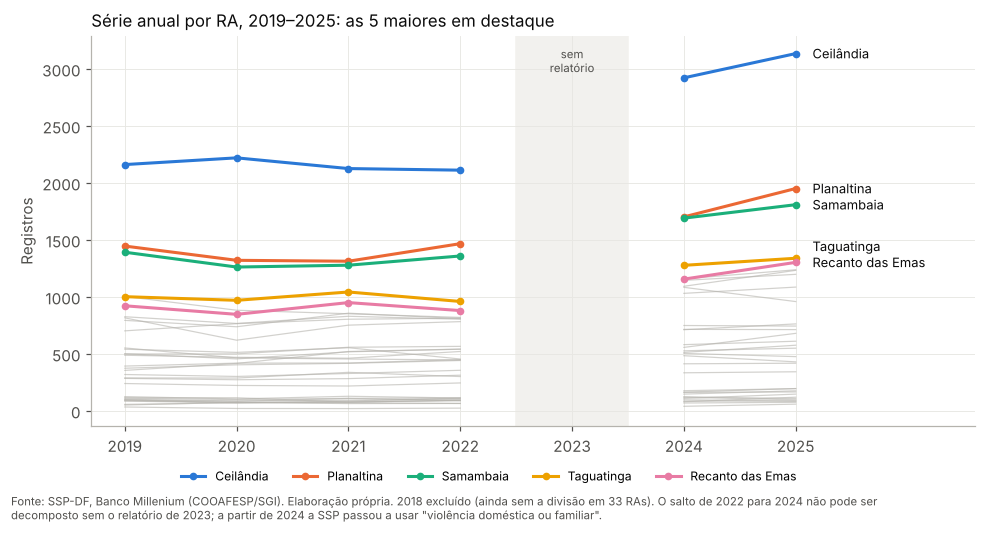

In [9]:
destaque = list(rank.head(5).index)
anos = list(range(anos33[0], ANO_ALVO + 1))            # anos sem relatório ficam vazios (linha interrompida)
serie = tab.reindex(columns=anos)
fig, ax = plt.subplots(figsize=(9, 4.8))
for ra in serie.index:
    if ra not in destaque:
        ax.plot(anos, serie.loc[ra], color=CINZA, lw=0.8, alpha=0.6)
cores5 = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
for ra, c in zip(destaque, cores5):
    ax.plot(anos, serie.loc[ra], color=c, lw=2, marker='o', ms=4, label=ra)
# rótulos no fim das linhas, afastados para não se sobreporem
ys = serie.loc[destaque, anos[-1]].sort_values()
pos, gap = [], serie.max().max() * 0.045
for ra, yv in ys.items():
    yv = max(yv, pos[-1][1] + gap) if pos else yv
    pos.append((ra, yv))
for ra, yv in pos:
    ax.text(anos[-1] + 0.15, yv, ra, color=TINTA, va='center', fontsize=8.5)
ausentes = [a for a in anos if serie[a].isna().all()]
for a in ausentes:
    ax.axvspan(a - 0.5, a + 0.5, color='#f2f1ee', zorder=0)
    ax.text(a, ax.get_ylim()[1] * 0.97, 'sem\nrelatório', ha='center', va='top', fontsize=7.5, color=TINTA2)
ax.set_xticks(anos)
ax.set_xlim(anos[0] - 0.3, anos[-1] + 1.6)
ax.set_ylabel('Registros')
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.45, -0.08), ncol=5)
ax.set_title(f'Série anual por RA, {anos[0]}–{ANO_ALVO}: as 5 maiores em destaque', loc='left', color=TINTA, fontsize=11)
fig.text(0.01, 0.005, FONTE + ' 2018 excluído (ainda sem a divisão em 33 RAs). O salto de 2022 para 2024 não pode ser\n'
         'decomposto sem o relatório de 2023; a partir de 2024 a SSP passou a usar "violência doméstica ou familiar".', fontsize=7.5, color=TINTA2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / 'fig4_serie_historica.png', bbox_inches='tight'); plt.show()

## 4.5 Agrupamento K-means

Técnica de **aprendizado não supervisionado** para agrupar RAs com perfis parecidos. Atributos de cada RA:

- `part_alvo`: participação no total do DF em 2025 (%), que mede o **volume**;
- `var_pct`: variação % de 2024 para 2025, que mede a **mudança recente**.

Só entram atributos de 2024–2025, que vêm do **mesmo relatório** (RAC-001/2026). A série anterior a 2024 não foi usada como atributo porque o salto de 2022 para 2024 (+28%) pode misturar aumento real com mudança de critério (ver Fase 5).

Os atributos são padronizados (`StandardScaler`), e *k* é escolhido pelo **coeficiente de silhueta** (design de teste: k de 2 a 4; com apenas 33 RAs, mais grupos ficariam pequenos demais para interpretar).

In [10]:
X = pd.DataFrame({
    'part_alvo': rank[f'part_{ANO_ALVO}_%'],
    'var_pct': rank['var_pct'],
}).loc[rank.index]
Xs = StandardScaler().fit_transform(X)

sil = {k: silhouette_score(Xs, KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(Xs)) for k in range(2, 5)}
print('Silhueta por k:', {k: round(s, 3) for k, s in sil.items()})
K = max(sil, key=sil.get)
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Xs)
X['grupo'] = km.labels_
perfil = X.groupby('grupo').agg(n_RAs=('part_alvo', 'size'), part_media=('part_alvo', 'mean'),
                                 var_pct_media=('var_pct', 'mean')).round(2)
perfil['RAs'] = X.groupby('grupo').apply(lambda g: ', '.join(g.index), include_groups=False)
print(f'k escolhido = {K} (silhueta {sil[K]:.3f})')
perfil.sort_values('part_media', ascending=False)

Silhueta por k: {2: 0.415, 3: 0.459, 4: 0.424}
k escolhido = 3 (silhueta 0.459)


,n_RAs,part_media,var_pct_media,RAs
grupo,,,,
0,9,6.88,8.46,"Ceilândia, Planaltina, Samambaia, Taguatinga, ..."
1,18,1.78,-0.91,"Brasília, Paranoá, Itapoã, Sobradinho II, Guar..."
2,6,0.98,32.28,"Estrutural, Jardim Botânico, Núcleo Bandeirant..."


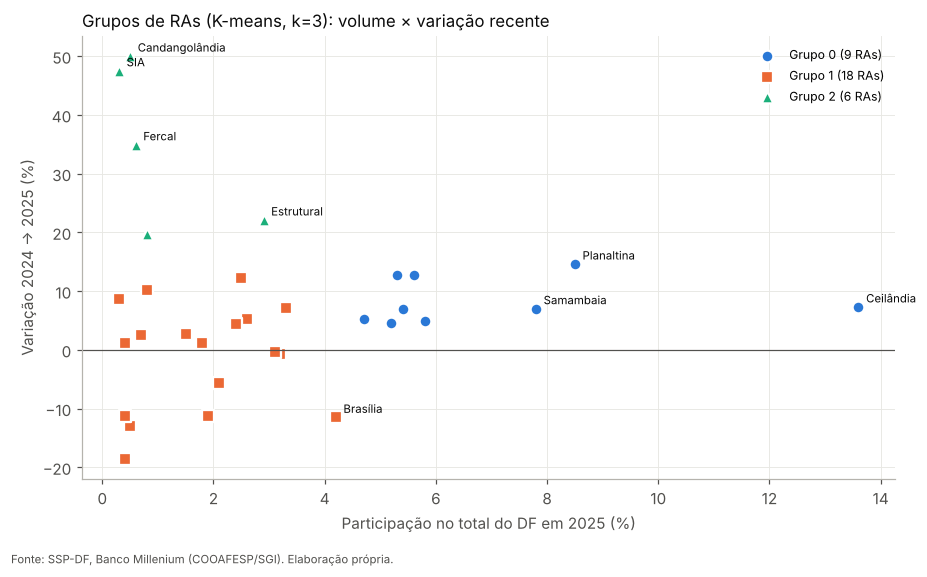

In [11]:
ordem_g = perfil.sort_values('part_media', ascending=False).index
cores_g = dict(zip(ordem_g, ['#2a78d6', '#eb6834', '#1baf7a', '#e34948', '#6250d6', '#008300']))
marc_g = dict(zip(ordem_g, ['o', 's', '^', 'D', 'v', 'P']))
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for g in ordem_g:
    d = X[X['grupo'] == g]
    ax.scatter(d['part_alvo'], d['var_pct'], s=60, color=cores_g[g], marker=marc_g[g],
               edgecolor='white', linewidth=1.5, label=f'Grupo {g} ({len(d)} RAs)')
rotulos = X[(X['part_alvo'] >= 7) | (X['var_pct'].abs() >= 20)].index.union(['Brasília'])
for ra in rotulos:
    ax.annotate(ra, (X.loc[ra, 'part_alvo'], X.loc[ra, 'var_pct']), xytext=(5, 3),
                textcoords='offset points', fontsize=7.5, color=TINTA)
ax.axhline(0, color=TINTA2, lw=0.8)
ax.set_xlabel(f'Participação no total do DF em {ANO_ALVO} (%)')
ax.set_ylabel(f'Variação {ANO_BASE} → {ANO_ALVO} (%)')
ax.set_title(f'Grupos de RAs (K-means, k={K}): volume × variação recente', loc='left', color=TINTA, fontsize=11)
ax.legend(frameon=False, fontsize=8)
fig.text(0.01, 0.005, FONTE, fontsize=7.5, color=TINTA2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / 'fig5_kmeans.png', bbox_inches='tight'); plt.show()

## Saídas da modelagem

In [12]:
saida = rank.join(X[['grupo']])
saida.index.name = 'ra'
saida.to_csv(RAIZ / 'dados' / 'processados' / f'resultado_modelagem_{ANO_BASE}_{ANO_ALVO}.csv', encoding='utf-8-sig')
saida.round(2)

,reg_2024,reg_2025,part_2025_%,pos_2024,pos_2025,soma_2_anos,pos_2_anos,var_abs,var_pct,grupo
ra,,,,,,,,,,
Ceilândia,2922,3135,13.6,1,1,6057,1,213,7.3,0
Planaltina,1702,1951,8.5,2,2,3653,2,249,14.6,0
Samambaia,1691,1809,7.8,3,3,3500,3,118,7.0,0
Taguatinga,1277,1339,5.8,4,4,2616,4,62,4.9,0
Recanto das Emas,1156,1303,5.6,6,5,2459,5,147,12.7,0
Gama,1158,1238,5.4,5,6,2396,6,80,6.9,0
Sol Nascente/Pôr do Sol,1093,1233,5.3,8,7,2326,8,140,12.8,0
Santa Maria,1145,1198,5.2,7,8,2343,7,53,4.6,0
São Sebastião,1031,1086,4.7,10,9,2117,9,55,5.3,0
